1. Data Preparation

In [1]:
from pathlib import Path

import numpy as np
from skimage import color, exposure, filters
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [12]:
# Dataset importing

subset_path = (Path("data")/ "processed"/ "cifar10_first4class_first50images.npz")

data = np.load(subset_path)

images = data["images"]
labels = data["labels"]
class_names = data["class_names"]

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Image shape: (200, 32, 32, 3)
Label shape: (200,)


In [11]:
# Existing functions from the assignment 1

def angle(dx, dy):
    """Calculate unsigned edge angles."""
    return np.mod(np.arctan2(dy, dx), np.pi)


def edge_histogram(rgb_image, number_of_bins=36):
    """Convert one RGB image into a 36-bin edge histogram."""
    
    gray_image = color.rgb2gray(rgb_image)
    
    horizontal_edges = filters.sobel_h(gray_image)
    vertical_edges = filters.sobel_v(gray_image)
    
    edge_angles = angle(horizontal_edges, vertical_edges)
    
    histogram, _ = exposure.histogram(
        edge_angles,
        nbins=number_of_bins
    )
    
    return histogram

In [4]:
histogram_list = []

for image in images:
    histogram = edge_histogram(image)
    histogram_list.append(histogram)

X = np.array(histogram_list)
y = labels.copy()

print("Feature matrix shape:", X.shape)

Feature matrix shape: (200, 36)


In [5]:
unique_classes = np.unique(y)

number_of_images = len(images)
number_of_classes = len(unique_classes)
feature_dimension = X.shape[1]

print("Number of images:", number_of_images)
print("Number of classes:", number_of_classes)
print("Feature vector dimension:", feature_dimension)

print("\nNumber of images in each class:")

for class_id in unique_classes:
    class_count = np.sum(y == class_id)
    class_name = class_names[y == class_id][0]
    
    print(f"Class {class_id} ({class_name}): " f"{class_count} images")

Number of images: 200
Number of classes: 4
Feature vector dimension: 36

Number of images in each class:
Class 0 (airplane): 50 images
Class 1 (automobile): 50 images
Class 2 (bird): 50 images
Class 3 (cat): 50 images


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

print("Class distribution after splitting:")

for class_id in unique_classes:
    class_name = class_names[y == class_id][0]
    
    training_count = np.sum(y_train == class_id)
    test_count = np.sum(y_test == class_id)
    
    print(f"{class_name}: "f"training = {training_count}, "f"test = {test_count}")

Training feature shape: (160, 36)
Test feature shape: (40, 36)
Class distribution after splitting:
airplane: training = 40, test = 10
automobile: training = 40, test = 10
bird: training = 40, test = 10
cat: training = 40, test = 10


In [10]:
scaler = StandardScaler()

# Means and variances only from the training data
X_train_standardized = scaler.fit_transform(X_train)

# Apply the same to the test data
X_test_standardized = scaler.transform(X_test)

print("Standardized training shape:",X_train_standardized.shape)

print("Standardized test shape:",X_test_standardized.shape)

# Sanity check to guarantee the normalization work
print("Largest absolute training feature mean:", np.max(np.abs(X_train_standardized.mean(axis=0)))) # close to 0

print("Smallest training feature standard deviation:",X_train_standardized.std(axis=0).min()) # close to 0

print("Largest training feature standard deviation:",X_train_standardized.std(axis=0).max()) # close to 1

Standardized training shape: (160, 36)
Standardized test shape: (40, 36)
Largest absolute training feature mean: 1.9220736113823022e-16
Smallest training feature standard deviation: 0.9999999999999993
Largest training feature standard deviation: 1.0000000000000007


The test set should simulate truly unseen data. If the entire dataset is used to calculate the mean and variance, information from the test set leaks into the training process, which compromises the test results and prevents them from serving as an independent, unbiased assessment of generalization performance.

2. Performance Comparison

In [14]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier

In [16]:
# classifier initialization from scikit-learn

classifiers_dict = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10),
    
    "Neural Network": MLPClassifier(hidden_layer_sizes=(10, 10, 10)),
    
    "AdaBoost": AdaBoostClassifier()
}

In [17]:
cross_validation = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

np.random.seed(42)

validation_results = []

for classifier_name, classifier in classifiers_dict.items():
    
    fold_accuracies = cross_val_score(
                        classifier,
                        X_train_standardized,
                        y_train,
                        cv=cross_validation,
                        scoring="accuracy"
                    )
    
    mean_accuracy = fold_accuracies.mean()
    standard_deviation = fold_accuracies.std()
    
    validation_results.append({"Classifier": classifier_name, "Mean Validation Accuracy": mean_accuracy, "Standard Deviation": standard_deviation})
    
    print(classifier_name)
    print("Fold accuracies:", np.round(fold_accuracies, 4))
    print()

Decision Tree
Fold accuracies: [0.25   0.375  0.3125 0.25   0.375 ]

Neural Network
Fold accuracies: [0.3125 0.4375 0.3438 0.3438 0.4688]



d:\DM_Programming_Assignment\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\DM_Programming_Assignment\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\DM_Programming_Assignment\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\DM_Programming_Assignment\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\DM_Programming_Assignment\.ve

AdaBoost
Fold accuracies: [0.4062 0.5312 0.3125 0.3438 0.4375]



In [18]:
results_table = pd.DataFrame(validation_results)

display(
    results_table.round({
        "Mean Validation Accuracy": 4,
        "Standard Deviation": 4
    })
)

,Classifier,Mean Validation Accuracy,Standard Deviation
0,Decision Tree,0.3125,0.0559
1,Neural Network,0.3812,0.0606
2,AdaBoost,0.4062,0.0765


Because AdaBoost achieved the highest average validation accuracy; therefore, I would select AdaBoost. However, it also exhibits the largest standard deviation among the three models, indicating that its performance across different folds is less stable than that of the other two. 
Furthermore, its average accuracy is only about 2.5 percentage points higher than that of the neural network, suggesting a relatively small advantage. Besides, the test set should not be used here to assist in model selection.

In [21]:
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score,f1_score, confusion_matrix,ConfusionMatrixDisplay)

class_ids = np.unique(y)
class_labels = ['airplane', 'automobile', 'bird', 'cat']

In [22]:
np.random.seed(42)

test_results = []
test_predictions = {}
confusion_matrices = {}

for classifier_name, classifier in classifiers_dict.items():
    
    # Train on the entire training set
    classifier.fit(X_train_standardized, y_train)
    
    y_pred = classifier.predict(X_test_standardized)
    
    test_accuracy = accuracy_score(y_test, y_pred)
    
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    
    matrix = confusion_matrix(y_test, y_pred, labels=class_ids)
    
    test_results.append({
        "Classifier": classifier_name,
        "Test Accuracy": test_accuracy,
        "Macro F1-score": macro_f1
    })
    
    test_predictions[classifier_name] = y_pred
    confusion_matrices[classifier_name] = matrix

d:\DM_Programming_Assignment\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [23]:
test_results_table = pd.DataFrame(test_results)

display(
    test_results_table.round({
        "Test Accuracy": 4,
        "Macro F1-score": 4
    })
)

,Classifier,Test Accuracy,Macro F1-score
0,Decision Tree,0.225,0.2036
1,Neural Network,0.400,0.4051
2,AdaBoost,0.375,0.3823


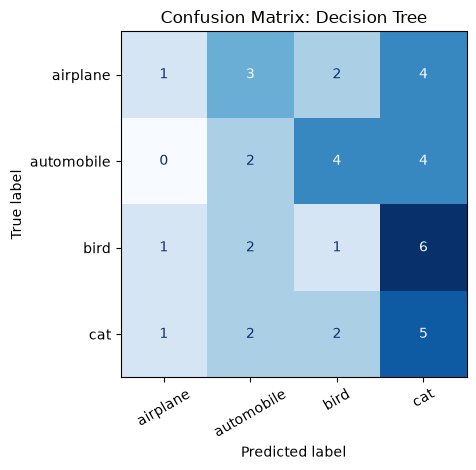

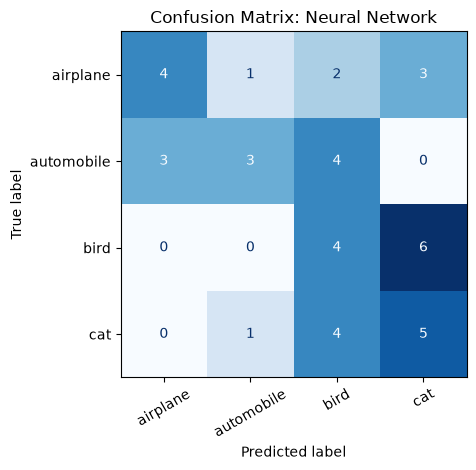

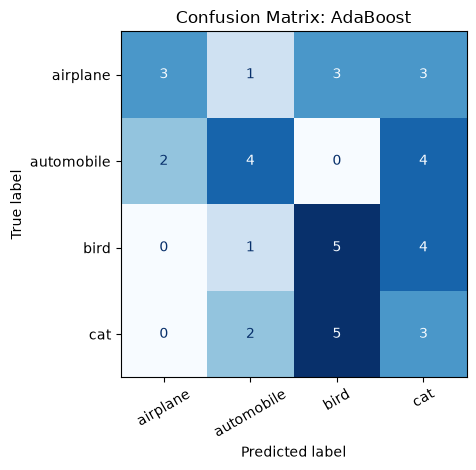

In [24]:
for classifier_name in classifiers_dict:
    
    matrix = confusion_matrices[classifier_name]
    
    display_matrix = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_labels)
    
    display_matrix.plot(cmap="Blues", values_format="d", colorbar=False)
    
    plt.title(f"Confusion Matrix: {classifier_name}")
    
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [25]:
for classifier_name, matrix in confusion_matrices.items():
    
    largest_confusion_count = -1
    most_confused_pair = None
    
    for first_class in range(len(class_ids)):
        for second_class in range(first_class + 1,len(class_ids)):
            
            confusion_count = (matrix[first_class, second_class] + matrix[second_class, first_class])
            
            if confusion_count > largest_confusion_count:
                largest_confusion_count = confusion_count
                most_confused_pair = (first_class, second_class)
    
    first_class, second_class = most_confused_pair
    
    print(classifier_name)
    print("Most confused pair:", class_labels[first_class], "and", class_labels[second_class])
    print("Total confusion count:", largest_confusion_count)
    print()

Decision Tree
Most confused pair: bird and cat
Total confusion count: 8

Neural Network
Most confused pair: bird and cat
Total confusion count: 10

AdaBoost
Most confused pair: bird and cat
Total confusion count: 9



The most frequently confused pair is bird and cat. This is the most confused pair for all three classifiers. The Decision Tree confused the pair 8 times, the Neural Network confused it 10 times, and AdaBoost confused it 9 times.

One possible explanation is that both birds and cats possess object boundaries that are irregular and curved. In small, 32×32-pixel CIFAR-10 images, details such as faces, beaks, ears, and legs are often not clearly defined. In addition, while a 36-dimensional edge histogram can capture the overall distribution of edge orientations, it fails to preserve the spatial locations of these edges. Consequently, even though images of birds and cats represent different objects, their edge histograms may still be quite similar.


In [27]:
all_image_indices = np.arange(len(images))

train_image_indices, test_image_indices = train_test_split(all_image_indices,test_size=0.20,random_state=42,stratify=y)

selected_classifier = "AdaBoost"
selected_predictions = test_predictions[selected_classifier]

bird_id = 2
cat_id = 3

bird_predicted_as_cat = np.where((y_test == bird_id) & (selected_predictions == cat_id))[0]

cat_predicted_as_bird = np.where((y_test == cat_id) & (selected_predictions == bird_id))[0]

selected_test_positions = [bird_predicted_as_cat[0], cat_predicted_as_bird[0]]

print("Selected test positions:", selected_test_positions)

Selected test positions: [np.int64(7), np.int64(5)]


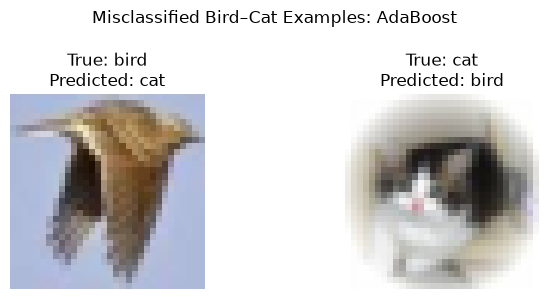

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

for axis, test_position in zip(axes, selected_test_positions):
    
    original_image_index = (test_image_indices[test_position])
    
    image = images[original_image_index]
    true_class = y_test[test_position]
    predicted_class = (selected_predictions[test_position])
    
    axis.imshow(image)
    
    axis.set_title(f"True: {class_labels[true_class]}\n" f"Predicted: {class_labels[predicted_class]}")
    
    axis.axis("off")

plt.suptitle("Misclassified Bird–Cat Examples: AdaBoost")

plt.tight_layout()
plt.show()

Based on the above two images, we can find that for the bird, its outline is not clearyly separated from the surrounding objects and for the cat image, it seems that the cat is curled into a compact shape, and its small size makes semantic details difficult to identify.

These errors are understandable because the images have a low resolution of 32 × 32 pixels. Furthermore, the edge-histogram representation discards color and spatial information. Therefore, visually different bird and cat images can still have similar 36-dimensional edge-histogram representations.

3. Model Selection and Model Complexity 

In [29]:
from sklearn.model_selection import (KFold, StratifiedKFold, cross_validate)

from sklearn.svm import LinearSVC

In [30]:
bird_id = 2
cat_id = 3

two_class_mask = np.isin(y_train,[bird_id, cat_id])

X_two_classes = X_train_standardized[two_class_mask]

y_two_classes = y_train[two_class_mask]

print("Feature matrix shape:", X_two_classes.shape)

print("Class IDs and counts:", np.unique(y_two_classes, return_counts=True))

Feature matrix shape: (80, 36)
Class IDs and counts: (array([2, 3]), array([40, 40]))


The two selected classes are bird and cat. These classes were selected because they were the most frequently confused pair in the confusion matrices from the previous section. 
The binary training dataset contains 80 images: 40 bird images and 40 cat images.

In [31]:
C_values = [0.01, 0.1, 1, 10, 100, 1000]

standard_cv = KFold(n_splits=5, shuffle=True, random_state=42)

stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [32]:
standard_training_errors = []
standard_validation_errors = []

stratified_training_errors = []
stratified_validation_errors = []

for C_value in C_values:
    
    classifier = LinearSVC(C=C_value)
    
    # Standard 5-fold cross-validation
    standard_scores = cross_validate(classifier, X_two_classes, y_two_classes, cv=standard_cv, scoring="accuracy", return_train_score=True)
    
    standard_training_error = (1 - standard_scores["train_score"].mean()) * 100
    
    standard_validation_error = (1 - standard_scores["test_score"].mean()) * 100
    
    standard_training_errors.append(standard_training_error)
    
    standard_validation_errors.append(standard_validation_error)
    
    # Stratified 5-fold cross-validation
    stratified_scores = cross_validate(classifier,X_two_classes,y_two_classes,cv=stratified_cv,scoring="accuracy",return_train_score=True)
    
    stratified_training_error = (1 - stratified_scores["train_score"].mean()) * 100
    
    stratified_validation_error = (1 - stratified_scores["test_score"].mean()) * 100
    
    stratified_training_errors.append(stratified_training_error)
    
    stratified_validation_errors.append(stratified_validation_error)

In [33]:
error_results = pd.DataFrame({
    "C": C_values,
    "Standard Training Error (%)":
        standard_training_errors,
    "Standard Validation Error (%)":
        standard_validation_errors,
    "Stratified Training Error (%)":
        stratified_training_errors,
    "Stratified Validation Error (%)":
        stratified_validation_errors
})

display(error_results.round(4))

,C,Standard Training Error (%),Standard Validation Error (%),Stratified Training Error (%),Stratified Validation Error (%)
0,0.01,20.3125,38.75,18.4375,37.50
1,0.10,12.5000,42.50,10.3125,46.25
2,1.00,8.4375,45.00,5.6250,47.50
3,10.00,5.3125,42.50,1.5625,46.25
4,100.00,2.8125,42.50,0.3125,46.25
5,1000.00,2.8125,42.50,0.0000,43.75


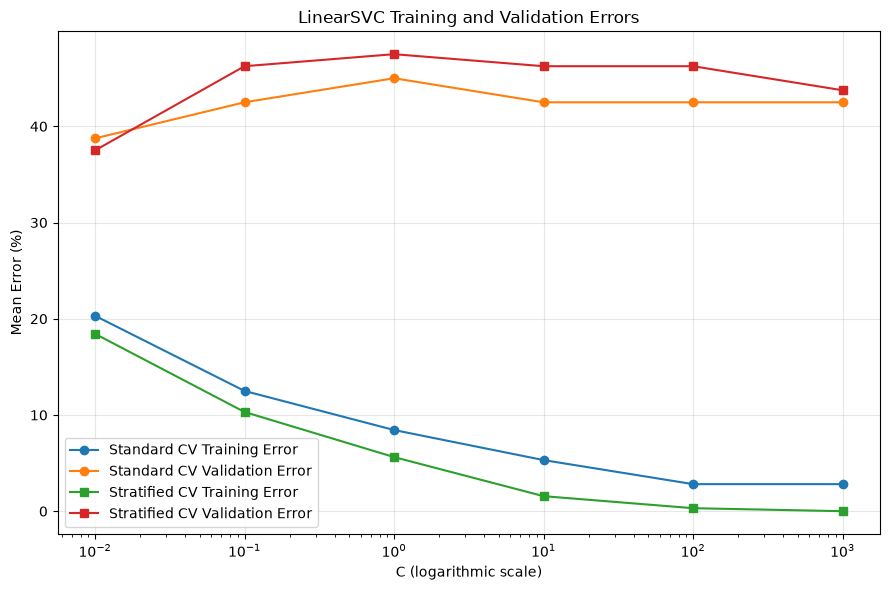

In [34]:
plt.figure(figsize=(9, 6))

plt.plot(C_values, standard_training_errors, marker="o", label="Standard CV Training Error")

plt.plot(C_values, standard_validation_errors, marker="o", label="Standard CV Validation Error")

plt.plot(C_values, stratified_training_errors, marker="s", label="Stratified CV Training Error")

plt.plot(C_values, stratified_validation_errors, marker="s", label="Stratified CV Validation Error")

plt.xscale("log")

plt.xlabel("C (logarithmic scale)")

plt.ylabel("Mean Error (%)")

plt.title("LinearSVC Training and Validation Errors")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

1. Which C gives the lowest mean validation error?

Ans: For standard 5-fold cross-validation, C = 0.01 gives the lowest mean validation error of 38.75%. For stratified 5-fold cross-validation, C = 0.01 also gives the lowest mean validation error, which is 37.50%.

2. How does increasing C affect model complexity?
Ans: Increasing C decreases the strength of regularization. The classifier places a larger penalty on training errors and attempts to classify the training observations more precisely.
Therefore, a larger C generally produces a more complex model decision result.

3. Is there evidence of underfitting?
Ans: At C = 0.01, the model is somewhat a little bit underfitting since it produces the highest training errors: 20.31% for standard cross-validation and 18.44% for stratified cross-validation for this value.
However, at this point it still exhibits the lowest validation error, suggesting that the stronger regularization provides the best generalization.

4. Is there evidence of overfitting?
Ans: As C increases, the training error becomes very small, while the validation error remains high. The large gap between the training and validation errors is strong evidence of overfitting.

5. Are the standard and stratified CV results similar?
Ans: The overall trends for both methods are similar:
    - Both achieve the lowest validation error at C=0.01;
    - Training error decreases as C increases;
    - Larger values ​​of C result in clear overfitting.

To further investigate the differences, we attempted to print the class distribution for each validation fold as follows:

In [37]:
print("Standard 5-fold validation distributions:")

for fold_number, (training_indices, validation_indices) in enumerate(standard_cv.split(X_two_classes), start=1):
    
    validation_labels = y_two_classes[validation_indices]
    
    class_ids_in_fold, class_counts = (np.unique(validation_labels, return_counts=True))
    
    print(f"Fold {fold_number}:",dict(zip(class_ids_in_fold, class_counts)))

print()
print("Stratified 5-fold validation distributions:")

for fold_number, (training_indices, validation_indices) in enumerate(stratified_cv.split(X_two_classes, y_two_classes), start=1):
    
    validation_labels = y_two_classes[validation_indices]
    
    class_ids_in_fold, class_counts = (np.unique(validation_labels, return_counts=True))
        
    print(f"Fold {fold_number}:",dict(zip(class_ids_in_fold, class_counts)))


Standard 5-fold validation distributions:
Fold 1: {np.int64(2): np.int64(5), np.int64(3): np.int64(11)}
Fold 2: {np.int64(2): np.int64(10), np.int64(3): np.int64(6)}
Fold 3: {np.int64(2): np.int64(9), np.int64(3): np.int64(7)}
Fold 4: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}
Fold 5: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}

Stratified 5-fold validation distributions:
Fold 1: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}
Fold 2: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}
Fold 3: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}
Fold 4: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}
Fold 5: {np.int64(2): np.int64(8), np.int64(3): np.int64(8)}


In [38]:
two_class_test_mask = np.isin(y_test, [bird_id, cat_id])

X_two_classes_test = X_test_standardized[two_class_test_mask]

y_two_classes_test = y_test[two_class_test_mask]

print("Two-class training shape:", X_two_classes.shape)

print("Two-class test shape:", X_two_classes_test.shape)

print("Test class distribution:", np.unique(y_two_classes_test, return_counts=True))

Two-class training shape: (80, 36)
Two-class test shape: (20, 36)
Test class distribution: (array([2, 3]), array([10, 10]))


In [39]:
best_stratified_index = np.argmin(stratified_validation_errors)

best_stratified_C = C_values[best_stratified_index]

final_svc = LinearSVC(C=best_stratified_C)

final_svc.fit(X_two_classes, y_two_classes)

y_test_predicted = final_svc.predict(X_two_classes_test)

print("Selected C:", best_stratified_C)

Selected C: 0.01


In [41]:
test_accuracy = accuracy_score(y_two_classes_test,y_test_predicted)

test_error = 1 - test_accuracy

cross_validation_error = (stratified_validation_errors[best_stratified_index] / 100)

error_difference = (test_error - cross_validation_error)

print("Test accuracy:", f"{test_accuracy * 100:.2f}%")

print("Test classification error:", f"{test_error * 100:.2f}%")

print("Mean cross-validation error:", f"{cross_validation_error * 100:.2f}%")

print("Difference:", f"{error_difference * 100:.2f} percentage points")

final_confusion_matrix = confusion_matrix(y_two_classes_test, y_test_predicted, labels=[bird_id, cat_id])

print(final_confusion_matrix)

Test accuracy: 45.00%
Test classification error: 55.00%
Mean cross-validation error: 37.50%
Difference: 17.50 percentage points
[[3 7]
 [4 6]]


Stratified 5-fold cross-validation selected C = 0.01, with a mean validation error of 37.50%. 
A LinearSVC with this value of C was trained on the entire two-class training set and evaluated on the held-out two-class test set. The test accuracy was 45.00%, with a classification error of 55.00%.

The test error is 17.50 percentage points higher than the mean cross-validation error, so the two errors are not closely consistent numerically.
However, considering the held-out test set contains only 20 images, with 10 images from each class. Each incorrectly classified image therefore changes the test error by 5 percentage points. This small test-set size can lead to considerable sampling variability.

4. Final Analysis: What Did You Learn?

According to the correct model selection process, I will temporarily choose AdaBoost.
It achieved the highest average cross-validation accuracy of 50% with a standard deviation of 7.65%, which was also the largest among all.
On the held-out test set, the performance of the neural network was slightly better than that of AdaBoost: the accuracy and macro F1 score of the neural network were 40.00% and 40.51% respectively, while those of AdaBoost were 37.50% and 38.23%; the decision tree performed the worst, with scores of 22.50% and 20.36% respectively.
Since the test set should not be reused for model selection, and the differences between the models are relatively small, the current results are insufficient to prove that a certain classifier has a significant advantage.
All three confusion matrices show that bird and cat are the most prone to confusion. The overall performance is low, indicating that the global 36-dimensional edge histogram has limited ability to distinguish, as it loses the spatial position information of color and edges.
As for the next step, I will attempt to retain the HOG features of the local edge structures and conduct the same cross-validation comparison again.